In [ ]:
# Cell 1/ M1
%pip install -q easyocr pyyaml natsort lmdb python-bidi pandas nltk matplotlib opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Cell 3/ M2
import torch
print(torch.__version__, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - fix PyTorch install first")
!nvidia-smi

2.11.0+cu128 True
NVIDIA GeForce RTX 4050 Laptop GPU


In [ ]:
# Cell 6/ M3
import os, sys, subprocess, shutil
from pathlib import Path

WORK     = Path(r"D:\Projects\MediLens")
DATA_SRC = WORK / "easyocr_data"
EASYOCR  = WORK / "EasyOCR"
TRAINER  = EASYOCR / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

# clone EasyOCR once
if not EASYOCR.exists():
    subprocess.run(["git", "clone", "https://github.com/JaidedAI/EasyOCR.git", str(EASYOCR)], check=True)

# patch dataset.py (newer torch compatibility)
f = TRAINER / "dataset.py"
t = f.read_text(encoding="utf-8")
t = t.replace("from torch._utils import _accumulate", "from itertools import accumulate as _accumulate")
t = t.replace("data_loader_iter.next()", "next(data_loader_iter)")
t = t.replace("self.dataloader_iter_list[i].next()", "next(self.dataloader_iter_list[i])")
f.write_text(t, encoding="utf-8")

# patch test.py (all tensors on one device for CTC loss)
f = TRAINER / "test.py"
t = f.read_text(encoding="utf-8")
old = "cost = criterion(preds.log_softmax(2).permute(1, 0, 2), text_for_loss, preds_size, length_for_loss)"
new = ("cost = criterion(preds.log_softmax(2).permute(1, 0, 2), "
       "text_for_loss.to(device), preds_size.to(device), length_for_loss.to(device))")
if old in t:
    f.write_text(t.replace(old, new), encoding="utf-8"); print("Patched test.py")
elif new in t:
    print("test.py already patched")
else:
    raise RuntimeError("Expected criterion line not found in test.py")

# report any remaining old-style .next() calls
for p in TRAINER.glob("*.py"):
    for i, line in enumerate(p.read_text(encoding="utf-8").splitlines(), 1):
        if ".next()" in line:
            print("Still present:", p.name, i, line.strip())

# copy the dataset ONCE. Never overwrite: all_data also holds the augmented and held-out folders
dst = TRAINER / "all_data"
if dst.exists():
    print("all_data already exists -> NOT copying again")
else:
    shutil.copytree(DATA_SRC, dst)
for d in sorted(dst.iterdir()):
    print(d.name, len(list(d.glob("*.png"))), "images")

medical_test 780 images
medical_train 3120 images
medical_val 780 images


In [ ]:
# Cell 8
import easyocr, yaml, torch

easyocr.Reader(['en'], gpu=True)   # downloads english_g2.pth on first run
pre_path = Path.home() / ".EasyOCR" / "model" / "english_g2.pth"
assert pre_path.exists(), pre_path

number    = '0123456789'
symbol    = "!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~ €"
lang_char = 'ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'
n_classes = len(number + symbol + lang_char) + 1

sd = torch.load(pre_path, map_location="cpu")
head_key = next(k for k in sd if k.endswith("Prediction.weight"))
pre_classes = sd[head_key].shape[0]
heads_match = (pre_classes == n_classes)
print("pretrained classes:", pre_classes, "| yours:", n_classes, "| match:", heads_match)

cfg = dict(
    number=number, symbol=symbol, lang_char=lang_char,
    experiment_name='medical_prescription',
    train_data='all_data', valid_data='all_data/medical_val',
    manualSeed=1111, workers=0, batch_size=32, num_iter=10000, valInterval=500,
    saved_model=str(pre_path), FT=True,
    optim=False, lr=1.0, beta1=0.9, rho=0.95, eps=1e-8, grad_clip=5,
    select_data='medical_train', batch_ratio='1',
    total_data_usage_ratio=1.0, batch_max_length=64,
    imgH=64, imgW=600, rgb=False, contrast_adjust=False,
    sensitive=True, PAD=True, data_filtering_off=False,
    Transformation='None', FeatureExtraction='VGG',
    SequenceModeling='BiLSTM', Prediction='CTC',
    num_fiducial=20, input_channel=1, output_channel=256, hidden_size=256,
    decode='greedy', new_prediction=(not heads_match),
    freeze_FeatureFxtraction=False, freeze_SequenceModeling=False,
)

config_path = TRAINER / "config_files" / "medical_prescription.yaml"
config_path.write_text(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False), encoding="utf-8")
print("Wrote", config_path)

pretrained classes: 97 | yours: 97 | match: True
Wrote D:\Projects\MediLens\EasyOCR\trainer\config_files\medical_prescription.yaml


In [ ]:
# Cell 9 / M6
import os, yaml
import torch.backends.cudnn as cudnn
from train import train
from utils import AttrDict

with open(config_path, "r", encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character = opt.number + opt.symbol + opt.lang_char
os.makedirs(f"./saved_models/{opt.experiment_name}", exist_ok=True)

cudnn.benchmark = True
cudnn.deterministic = False

try:
    train(opt, amp=True)
except SystemExit:          # the trainer calls sys.exit() when it finishes
    pass

medical_train OK: 3120 samples
medical_val OK: 780 samples
Filtering the images containing characters which are not in opt.character
Filtering the images whose label is longer than opt.batch_max_length
--------------------------------------------------------------------------------
dataset_root: all_data
opt.select_data: ['medical_train']
opt.batch_ratio: ['1']
--------------------------------------------------------------------------------
dataset_root:    all_data	 dataset: medical_train
all_data/medical_train
sub-directory:	/medical_train	 num samples: 3120
num total samples of medical_train: 3120 x 1.0 (total_data_usage_ratio) = 3120
num samples of medical_train per batch: 32 x 1.0 (batch_ratio) = 32
--------------------------------------------------------------------------------
Total_batch_size: 32 = 32
--------------------------------------------------------------------------------
dataset_root:    all_data/medical_val	 dataset: /
all_data/medical_val/
sub-directory:	/.	 num sam

D:\Projects\MediLens\EasyOCR\trainer\train.py:172: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
D:\Projects\MediLens\EasyOCR\trainer\train.py:180: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


training time:  98.4116678237915
[500/10000] Train loss: 0.44523, Valid loss: 0.57670, Elapsed_time: 98.41267
Current_accuracy : 56.282, Current_norm_ED  : 0.8783
Best_accuracy    : 56.282, Best_norm_ED     : 0.8783
--------------------------------------------------------------------------------
Ground Truth              | Prediction                | Confidence Score & T/F
--------------------------------------------------------------------------------
Alatrol                   | Alotrol                   | 0.1860	False
Omastin                   | Omastin                   | 0.3419	True
--------------------------------------------------------------------------------
validation time:  15.961259603500366
training time:  92.78920030593872
[1000/10000] Train loss: 0.02427, Valid loss: 0.62030, Elapsed_time: 207.16313
Current_accuracy : 60.641, Current_norm_ED  : 0.8889
Best_accuracy    : 60.641, Best_norm_ED     : 0.8889
---------------------------------------------------------------------

SystemExit: 

d:\Projects\MediLens\medical-prescription-ocr\.venv\lib\site-packages\IPython\core\interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
# Cell 10 / M5
import pandas as pd
base = TRAINER / "all_data"

for split in ["medical_train", "medical_val", "medical_test"]:
    d = base / split
    chk = pd.read_csv(d / "labels.csv")
    assert list(chk.columns) == ["filename", "words"]
    assert len(chk) == len(list(d.glob("*.png")))
    assert all((d / n).exists() for n in chk["filename"])
    print(split, "OK:", len(chk), "samples")

tr = pd.read_csv(base/"medical_train"/"labels.csv")["words"]
va = pd.read_csv(base/"medical_val"/"labels.csv")["words"]
te = pd.read_csv(base/"medical_test"/"labels.csv")["words"]
print("unique names  train/val/test:", tr.nunique(), va.nunique(), te.nunique())
print("val rows with name seen in train: %.1f%%" % (va.isin(set(tr)).mean()*100))
print("test rows with name seen in train: %.1f%%" % (te.isin(set(tr)).mean()*100))

unique names  train/val/test: 78 78 78
val rows with name seen in train: 100.0%
test rows with name seen in train: 100.0%


In [ ]:
# Cell 11
import torch, numpy as np
from PIL import Image
from utils import CTCLabelConverter
from model import Model
from nltk.metrics.distance import edit_distance

device = torch.device("cuda")
converter = CTCLabelConverter(opt.character)
opt.num_class = len(converter.character)
model = torch.nn.DataParallel(Model(opt)).to(device)
ckpt = TRAINER/"saved_models"/"medical_prescription_aug"/"best_accuracy.pth"
model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)   # pad by repeating last column, as the trainer does
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

df = pd.read_csv(base/"medical_val"/"labels.csv")
preds = []
with torch.no_grad():
    for i in range(0, len(df), 64):
        names = df["filename"].iloc[i:i+64]
        x = torch.stack([prep(base/"medical_val"/n) for n in names]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        idx = out.argmax(2).view(-1).cpu()
        sizes = torch.IntTensor([out.size(1)] * len(x))
        preds += converter.decode_greedy(idx, sizes)

df["pred"] = preds
df["exact"] = df["words"] == df["pred"]
df["ed"] = [edit_distance(p, t) for p, t in zip(df["pred"], df["words"])]
print("exact match: %.2f%%" % (df["exact"].mean()*100))
print("CER: %.4f" % (df["ed"].sum() / df["words"].str.len().sum()))
print("seen-in-train exact: %.1f%%" % (df[df["words"].isin(set(tr))]["exact"].mean()*100))
print("unseen exact:        %.1f%%" % (df[~df["words"].isin(set(tr))]["exact"].mean()*100))
df[~df["exact"]].head(30)

import difflib
vocab = sorted(set(tr))

def snap(p):
    m = difflib.get_close_matches(p, vocab, n=1, cutoff=0.0)
    return m[0] if m else p

df["snapped"] = df["pred"].map(snap)
print("exact after vocab snapping: %.2f%%" % ((df["snapped"] == df["words"]).mean() * 100))
df[~df["exact"]][["words", "pred", "snapped"]].head(30)

No Transformation module specified
exact match: 54.74%
CER: 0.1360
seen-in-train exact: 54.7%
unseen exact:        nan%
exact after vocab snapping: 93.72%


,words,pred,snapped
3,Aceta,Acata,Aceta
5,Aceta,Acet,Aceta
6,Aceta,Acata,Aceta
7,Aceta,Acata,Aceta
8,Aceta,Acata,Aceta
10,Ace,Aca,Aceta
11,Ace,Aca,Aceta
13,Ace,Aca,Aceta
22,Alatrol,Alatrel,Alatrol
24,Alatrol,Alatral,Alatrol


In [ ]:
# Cell 12
from nltk.metrics.distance import edit_distance

vocab = sorted(set(tr))

def snap(p, max_norm=0.5):
    best = min(vocab, key=lambda v: edit_distance(p, v))
    d = edit_distance(p, best)
    return best if d / max(len(best), 1) <= max_norm else p   # too far -> keep raw OCR

df["snapped"] = df["pred"].map(snap)
print("exact after snapping: %.2f%%" % ((df["snapped"] == df["words"]).mean() * 100))
df[df["snapped"] != df["words"]][["words", "pred", "snapped"]].head(30)

exact after snapping: 93.33%


,words,pred,snapped
5,Aceta,Acet,Ace
41,Atrizin,Atmcism,Atmcism
141,Beklo,Bcicio,Bcicio
145,Beklo,ab Beklumy,ab Beklumy
231,Dinafex,Fixal,Fixal
242,Disopan,Bicopax,Bacmax
272,Etizin,Extaen,Extaen
277,Etizin,Extein,Axodin
279,Etizin,Eitotn,Eitotn
281,Exium,T,T


In [ ]:
# Cell 13
import cv2, random, shutil
import numpy as np, pandas as pd
from pathlib import Path

random.seed(0); np.random.seed(0)
SRC = TRAINER / "all_data" / "medical_train"
DST = TRAINER / "all_data" / "medical_train_aug"
N_AUG = 4

if DST.exists():
    shutil.rmtree(DST)
DST.mkdir()

def augment(img):
    h, w = img.shape[:2]
    ang, shear, scale = random.uniform(-3, 3), random.uniform(-0.12, 0.12), random.uniform(0.92, 1.05)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, scale)
    M[0, 1] += shear
    M[0, 2] -= shear * h / 2
    out = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CellAR, borderMode=cv2.BORDER_REPLICATE)
    if random.random() < 0.5:
        k = random.choice([3, 5])
        out = cv2.GaussianBlur(out, (k, k), 0)
    if random.random() < 0.4:
        op = cv2.erode if random.random() < 0.5 else cv2.dilate
        out = op(out, np.ones((2, 2), np.uint8))
    out = cv2.convertScaleAbs(out, alpha=random.uniform(0.75, 1.25), beta=random.uniform(-25, 25))
    noise = np.random.normal(0, random.uniform(0, 10), out.shape)
    out = np.clip(out.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    if random.random() < 0.3:
        _, buf = cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, random.randint(35, 75)])
        out = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    return out

df_tr = pd.read_csv(SRC / "labels.csv")
rows = []
for fn, word in zip(df_tr["filename"], df_tr["words"]):
    shutil.copy2(SRC / fn, DST / fn)
    rows.append((fn, word))
    img = cv2.imread(str(SRC / fn), cv2.IMREAD_COLOR)
    assert img is not None, f"could not read {fn}"
    for i in range(N_AUG):
        new = f"{Path(fn).stem}_aug{i}.png"
        cv2.imwrite(str(DST / new), augment(img))
        rows.append((new, word))

pd.DataFrame(rows, columns=["filename", "words"]).to_csv(DST / "labels.csv", index=False)
print(len(rows), "training images written to", DST)

15600 training images written to D:\Projects\MediLens\EasyOCR\trainer\all_data\medical_train_aug


In [ ]:
# Cell 14
import gc, torch, numpy as np, pandas as pd
import torch.nn.functional as F
from PIL import Image
from utils import CTCLabelConverter
from model import Model
from nltk.metrics.distance import edit_distance

# ---- change only this line between evaluations ----
EXPERIMENT = "medical_prescription_aug"        # later: "medical_prescription_aug"
# ---------------------------------------------------

device = torch.device("cuda")
base = TRAINER / "all_data"
tr = pd.read_csv(base / "medical_train" / "labels.csv")["words"]

globals().pop("model", None); gc.collect(); torch.cuda.empty_cache()

converter = CTCLabelConverter(opt.character)
opt.num_class = len(converter.character)
model = torch.nn.DataParallel(Model(opt)).to(device)
ckpt = TRAINER / "saved_models" / EXPERIMENT / "best_accuracy.pth"
model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

df = pd.read_csv(base / "medical_test" / "labels.csv")
vocab = sorted(set(tr))
v_text, v_len = converter.encode(vocab)
V = len(vocab)

raw_preds, ctc_words, ctc_conf = [], [], []
with torch.no_grad():
    for i in range(0, len(df), 64):
        names = df["filename"].iloc[i:i+64]
        x = torch.stack([prep(base / "medical_test" / n) for n in names]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))

        # plain greedy decode
        idx = out.argmax(2).view(-1).cpu()
        sizes = torch.IntTensor([out.size(1)] * len(x))
        raw_preds += converter.decode_greedy(idx, sizes)

        # score every vocabulary word with the model's CTC likelihood
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0,
                             reduction="none", zero_infinity=True)
            post = torch.softmax(-nll, dim=0)
            k = int(post.argmax())
            ctc_words.append(vocab[k]); ctc_conf.append(float(post[k]))

df["pred"], df["ctc_pred"], df["ctc_conf"] = raw_preds, ctc_words, ctc_conf
df["ed"] = [edit_distance(p, t) for p, t in zip(df["pred"], df["words"])]

print("checkpoint:", EXPERIMENT)
print("raw exact: %.2f%%   CER: %.4f" % ((df["pred"] == df["words"]).mean() * 100,
                                         df["ed"].sum() / df["words"].str.len().sum()))
print("CTC-vocab exact: %.2f%%" % ((df["ctc_pred"] == df["words"]).mean() * 100))
for th in (0.5, 0.8, 0.95):
    keep = df["ctc_conf"] >= th
    acc = (df[keep]["ctc_pred"] == df[keep]["words"]).mean() * 100 if keep.any() else float("nan")
    print(f"conf>={th}: covers {keep.mean()*100:.1f}%, accuracy on those {acc:.1f}%")

df[df["ctc_pred"] != df["words"]][["words", "pred", "ctc_pred", "ctc_conf"]].head(30)

No Transformation module specified
checkpoint: medical_prescription_aug
raw exact: 57.44%   CER: 0.1285
CTC-vocab exact: 96.67%
conf>=0.5: covers 100.0%, accuracy on those 96.7%
conf>=0.8: covers 99.2%, accuracy on those 96.9%
conf>=0.95: covers 98.7%, accuracy on those 97.1%


,words,pred,ctc_pred,ctc_conf
40,Atrizin,Azizin,Etizin,0.976315
108,Backtone,Backtin,Baclon,0.998722
141,Beklo,Baicho,Baclon,0.966691
159,Bicozin,Biloya,Fixal,0.944032
231,Dinafex,Fixal,Fixal,1.000000
279,Etizin,Eitot,Ritch,0.619705
281,Exium,Zeayy,Az,0.988406
291,Fenadin,Fexo,Fexo,1.000000
298,Fenadin,Fexo,Fexo,1.000000
313,Fexo,Fixcl,Fixal,1.000000


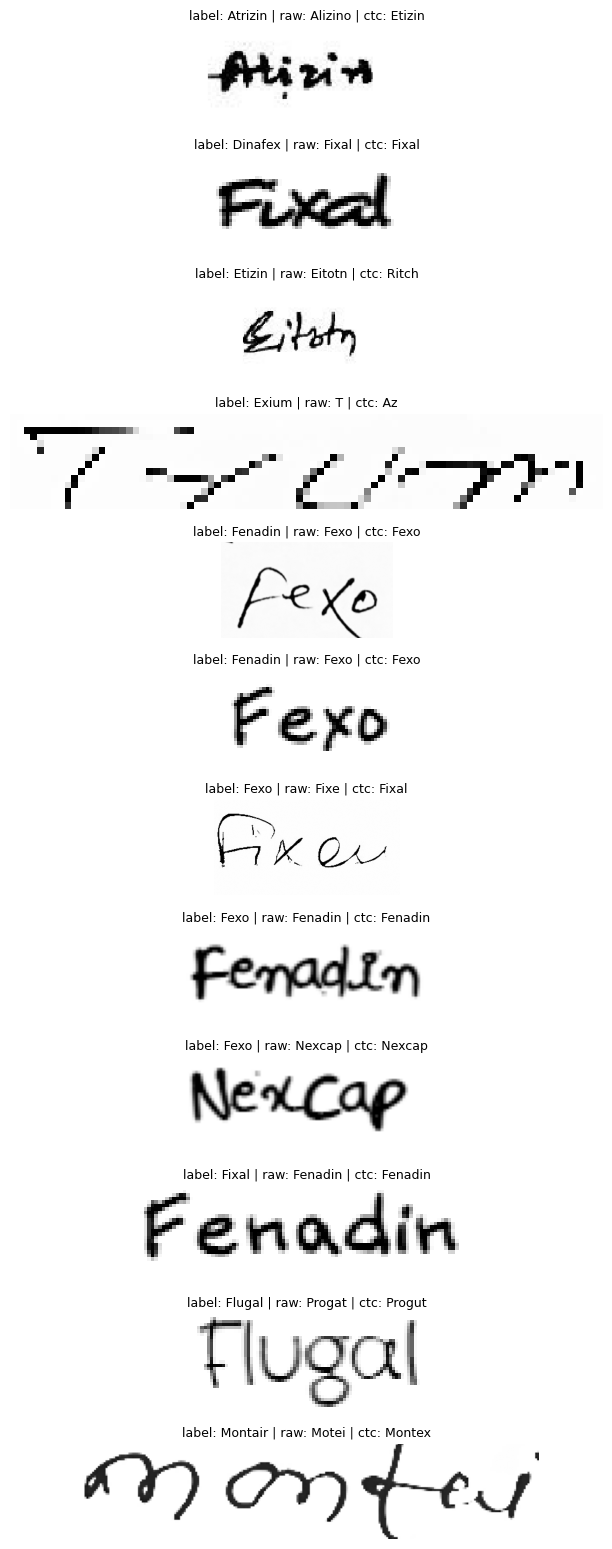

In [ ]:
# Cell 15
import matplotlib.pyplot as plt
bad = df[(df["ctc_pred"] != df["words"]) & (df["ctc_conf"] > 0.99)].head(12)
fig, axes = plt.subplots(len(bad), 1, figsize=(8, 1.3 * len(bad)))
for ax, (_, r) in zip(axes, bad.iterrows()):
    ax.imshow(Image.open(base / "medical_test" / r["filename"]).convert("L"), cmap="gray")
    ax.set_title(f'label: {r["words"]} | raw: {r["pred"]} | ctc: {r["ctc_pred"]}', fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Cell 16
df["disagree"] = [edit_distance(a, b) / max(len(b), 1) for a, b in zip(df["pred"], df["ctc_pred"])]
for th in (0.3, 0.5, 0.7):
    keep = df["disagree"] <= th
    acc = (df[keep]["ctc_pred"] == df[keep]["words"]).mean() * 100
    print(f"disagree<={th}: covers {keep.mean()*100:.1f}%, accuracy {acc:.1f}%")

disagree<=0.3: covers 85.3%, accuracy 98.0%
disagree<=0.5: covers 97.1%, accuracy 97.4%
disagree<=0.7: covers 98.5%, accuracy 97.1%


rows where both decoders agree on a different name: 10 of 1560


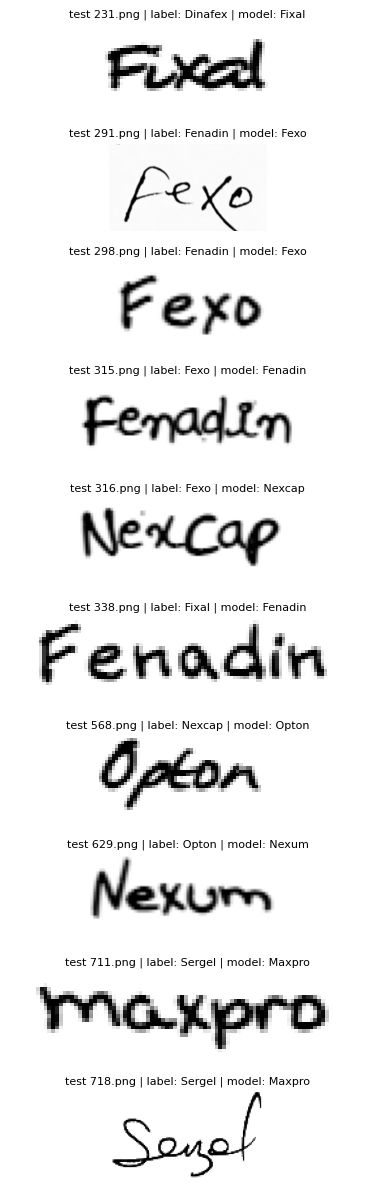

In [ ]:
# Cell 17
import matplotlib.pyplot as plt

def score_split(split):
    d = pd.read_csv(base / split / "labels.csv")
    raw, cw = [], []
    with torch.no_grad():
        for i in range(0, len(d), 64):
            names = d["filename"].iloc[i:i+64]
            x = torch.stack([prep(base / split / n) for n in names]).to(device)
            out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
            idx = out.argmax(2).view(-1).cpu()
            sizes = torch.IntTensor([out.size(1)] * len(x))
            raw += converter.decode_greedy(idx, sizes)
            logp = out.log_softmax(2).float().cpu()
            T, C = logp.size(1), logp.size(2)
            in_len = torch.full((V,), T, dtype=torch.int32)
            for b in range(len(x)):
                lp = logp[b][:, None, :].expand(T, V, C).contiguous()
                nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0,
                                 reduction="none", zero_infinity=True)
                cw.append(vocab[int(nll.argmin())])
    d["pred"], d["ctc_pred"], d["split"] = raw, cw, split
    return d

res = pd.concat([score_split("medical_val"), score_split("medical_test")], ignore_index=True)
flag = res[(res["pred"] == res["ctc_pred"]) & (res["ctc_pred"] != res["words"])].copy()
print("rows where both decoders agree on a different name:", len(flag), "of", len(res))
flag.to_csv(WORK / "flagged_labels.csv", index=False)

def show(rows, per_page=15):
    for s in range(0, len(rows), per_page):
        chunk = rows.iloc[s:s+per_page]
        fig, axes = plt.subplots(len(chunk), 1, figsize=(7, 1.2 * len(chunk)))
        axes = np.atleast_1d(axes)
        for ax, (_, r) in zip(axes, chunk.iterrows()):
            ax.imshow(Image.open(base / r["split"] / r["filename"]).convert("L"), cmap="gray")
            ax.set_title(f'{r["split"][-4:]} {r["filename"]} | label: {r["words"]} | model: {r["ctc_pred"]}', fontsize=8)
            ax.axis("off")
        plt.tight_layout(); plt.show()

show(flag)

In [ ]:
# Cell 18/ M7
import gc, shutil, yaml, torch, os
import pandas as pd
from train import train
from utils import AttrDict

# free any eval model and back up run 1
globals().pop("model", None)
gc.collect(); torch.cuda.empty_cache()
shutil.copy2(TRAINER/"saved_models"/"medical_prescription"/"best_accuracy.pth", MODELS/"run1_best_accuracy.pth")

# fresh opt from the config file
with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character    = opt.number + opt.symbol + opt.lang_char
opt.workers      = 1
opt.select_data  = 'medical_train_aug'
opt.experiment_name = 'medical_prescription_aug'
opt.lr           = 0.3
opt.num_iter     = 5000
opt.valInterval  = 250

aug = TRAINER/"all_data"/"medical_train_aug"
print("aug images:", len(list(aug.glob("*.png"))), "| rows:", len(pd.read_csv(aug/"labels.csv")))
print("start from:", opt.saved_model, "| FT:", opt.FT, "| new_prediction:", opt.new_prediction)

os.chdir(TRAINER)
os.makedirs(f"./saved_models/{opt.experiment_name}", exist_ok=True)
try:
    train(opt, amp=True)
except SystemExit:
    pass

# back up the final model
shutil.copy2(TRAINER/"saved_models"/"medical_prescription_aug"/"best_accuracy.pth", MODELS/"final_best_accuracy.pth")

aug images: 15600 | rows: 15600
start from: C:\Users\JAGADISH\.EasyOCR\model\english_g2.pth | FT: True | new_prediction: False
Filtering the images containing characters which are not in opt.character
Filtering the images whose label is longer than opt.batch_max_length
--------------------------------------------------------------------------------
dataset_root: all_data
opt.select_data: ['medical_train_aug']
opt.batch_ratio: ['1']
--------------------------------------------------------------------------------
dataset_root:    all_data	 dataset: medical_train_aug
all_data/medical_train_aug
sub-directory:	/medical_train_aug	 num samples: 15600
num total samples of medical_train_aug: 15600 x 1.0 (total_data_usage_ratio) = 15600
num samples of medical_train_aug per batch: 32 x 1.0 (batch_ratio) = 32
--------------------------------------------------------------------------------
Total_batch_size: 32 = 32
--------------------------------------------------------------------------------
dat

D:\Projects\MediLens\EasyOCR\trainer\train.py:172: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
D:\Projects\MediLens\EasyOCR\trainer\train.py:180: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


training time:  106.86123085021973
[250/5000] Train loss: 1.23130, Valid loss: 0.89396, Elapsed_time: 106.86123
Current_accuracy : 32.436, Current_norm_ED  : 0.7710
Best_accuracy    : 32.436, Best_norm_ED     : 0.7710
--------------------------------------------------------------------------------
Ground Truth              | Prediction                | Confidence Score & T/F
--------------------------------------------------------------------------------
Maxima                    | Mtxima                    | 0.0900	False
Tridosil                  | Tjaoil                    | 0.0083	False
--------------------------------------------------------------------------------
validation time:  12.029662847518921
training time:  107.39885711669922
[500/5000] Train loss: 0.65873, Valid loss: 0.72146, Elapsed_time: 226.28975
Current_accuracy : 40.769, Current_norm_ED  : 0.8247
Best_accuracy    : 40.769, Best_norm_ED     : 0.8247
-------------------------------------------------------------------

In [ ]:
# Cell 20
import random, shutil
import pandas as pd
from nltk.metrics.distance import edit_distance

base = TRAINER / "all_data"
names = sorted(set(pd.read_csv(base/"medical_train_aug"/"labels.csv")["words"]))

NOISY = {"Fenadin","Fexo","Fixal","Dinafex","Nexcap","Opton","Nexum","Sergel",
         "Maxpro","Exium","Montair","Montene","Bacaid"}

def ok(n):
    nl = n.lower()
    others = [m.lower() for m in names if m != n]
    if any(nl in m or m in nl for m in others):
        return False
    return min(edit_distance(nl, m) for m in others) >= 3

cands = [n for n in names if n not in NOISY and ok(n)]
print(len(cands), "eligible names")
assert len(cands) >= 8, "too few eligible names; relax the filter"

HOLDOUT = sorted(random.Random(0).sample(cands, 8))   # change the seed to repeat with other names
hold = set(HOLDOUT)
print("held-out names:", HOLDOUT)

def make_split(src_dir, dst_dir, keep_fn):
    df = pd.read_csv(src_dir/"labels.csv")
    df = df[df["words"].map(keep_fn)]
    if dst_dir.exists():
        shutil.rmtree(dst_dir)
    dst_dir.mkdir(parents=True)
    for fn in df["filename"]:
        shutil.copy2(src_dir/fn, dst_dir/fn)
    df.to_csv(dst_dir/"labels.csv", index=False)
    return len(df)

n_tr = make_split(base/"medical_train_aug", base/"holdout_train", lambda w: w not in hold)
n_va = make_split(base/"medical_val",       base/"holdout_val",   lambda w: w not in hold)
print("holdout_train:", n_tr, "| holdout_val:", n_va)

for d in ("holdout_train", "holdout_val"):
    assert not (set(pd.read_csv(base/d/"labels.csv")["words"]) & hold), d
print("no held-out name leaked into training or validation")

38 eligible names
held-out names: ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
holdout_train: 14000 | holdout_val: 700
no held-out name leaked into training or validation


In [ ]:
# Cell 21
import gc, os, yaml, torch
from utils import AttrDict

globals().pop("model", None); gc.collect(); torch.cuda.empty_cache()

with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character       = opt.number + opt.symbol + opt.lang_char
opt.workers         = 1
opt.select_data     = "holdout_train"
opt.valid_data      = "all_data/holdout_val"
opt.experiment_name = "holdout"
opt.lr              = 0.3
opt.num_iter        = 5000
opt.valInterval     = 250

print("starts from:", opt.saved_model, "| FT:", opt.FT, "| new_prediction:", opt.new_prediction)
assert "english_g2" in str(opt.saved_model) and opt.FT, "config was overwritten; do not train"

os.chdir(TRAINER)
os.makedirs(f"./saved_models/{opt.experiment_name}", exist_ok=True)
try:
    train(opt, amp=True)
except SystemExit:
    pass

starts from: C:\Users\JAGADISH\.EasyOCR\model\english_g2.pth | FT: True | new_prediction: False
Filtering the images containing characters which are not in opt.character
Filtering the images whose label is longer than opt.batch_max_length
--------------------------------------------------------------------------------
dataset_root: all_data
opt.select_data: ['holdout_train']
opt.batch_ratio: ['1']
--------------------------------------------------------------------------------
dataset_root:    all_data	 dataset: holdout_train
all_data/holdout_train
sub-directory:	/holdout_train	 num samples: 14000
num total samples of holdout_train: 14000 x 1.0 (total_data_usage_ratio) = 14000
num samples of holdout_train per batch: 32 x 1.0 (batch_ratio) = 32
--------------------------------------------------------------------------------
Total_batch_size: 32 = 32
--------------------------------------------------------------------------------
dataset_root:    all_data/holdout_val	 dataset: /
all_data

D:\Projects\MediLens\EasyOCR\trainer\train.py:172: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
D:\Projects\MediLens\EasyOCR\trainer\train.py:180: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


training time:  99.01514291763306
[250/5000] Train loss: 1.20648, Valid loss: 0.85412, Elapsed_time: 99.01514
Current_accuracy : 33.571, Current_norm_ED  : 0.7822
Best_accuracy    : 33.571, Best_norm_ED     : 0.7822
--------------------------------------------------------------------------------
Ground Truth              | Prediction                | Confidence Score & T/F
--------------------------------------------------------------------------------
Aceta                     | Aceta                     | 0.5008	True
Azithrocin                | Brithracin                | 0.0442	False
--------------------------------------------------------------------------------
validation time:  19.292929649353027
training time:  88.4551568031311
[500/5000] Train loss: 0.60670, Valid loss: 0.66567, Elapsed_time: 206.76323
Current_accuracy : 44.000, Current_norm_ED  : 0.8306
Best_accuracy    : 44.000, Best_norm_ED     : 0.8306
------------------------------------------------------------------------

In [ ]:
# Cell 22
import numpy as np, torch.nn.functional as F
from PIL import Image
from utils import CTCLabelConverter
from model import Model

device = torch.device("cuda")
converter = CTCLabelConverter(opt.character)
opt.num_class = len(converter.character)

def load(exp):
    m = torch.nn.DataParallel(Model(opt)).to(device)
    m.load_state_dict(torch.load(TRAINER/"saved_models"/exp/"best_accuracy.pth", map_location=device))
    return m.eval()

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

@torch.no_grad()
def run(model, paths, vocab):
    v_text, v_len = converter.encode(vocab); V = len(vocab)
    raw, pick = [], []
    for i in range(0, len(paths), 64):
        x = torch.stack([prep(p) for p in paths[i:i+64]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        idx = out.argmax(2).view(-1).cpu()
        sizes = torch.IntTensor([out.size(1)] * len(x))
        raw += converter.decode_greedy(idx, sizes)
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0, reduction="none", zero_infinity=True)
            pick.append(vocab[int(nll.argmin())])
    return raw, pick

def cer(preds, truths):
    return sum(edit_distance(p, t) for p, t in zip(preds, truths)) / sum(len(t) for t in truths)

# held-out images come from ALL splits (the model never saw these names)
parts = []
for split, tag in [("medical_train", "train"), ("medical_val", "val"), ("medical_test", "test")]:
    d = pd.read_csv(base/split/"labels.csv")
    d = d[d["words"].isin(hold)].copy()
    d["src"] = tag
    d["path"] = [str(base/split/f) for f in d["filename"]]
    parts.append(d)
held = pd.concat(parts, ignore_index=True)

# known-name control: test images of the 70 names the model did train on
known = pd.read_csv(base/"medical_test"/"labels.csv")
known = known[~known["words"].isin(hold)].copy()
known["path"] = [str(base/"medical_test"/f) for f in known["filename"]]

vocab70 = sorted(set(pd.read_csv(base/"holdout_train"/"labels.csv")["words"]))
new = load("holdout")
raw_h, pick_h = run(new, held["path"].tolist(), vocab70)
raw_k, pick_k = run(new, known["path"].tolist(), vocab70)
held["raw"] = raw_h
known["raw"], known["pick"] = raw_k, pick_k

print("==== OPEN SET: held-out names, never seen in training ====")
print("held-out names:", HOLDOUT, "| images:", len(held))
print("raw exact: %.2f%%   CER: %.4f" % ((held["raw"] == held["words"]).mean() * 100, cer(held["raw"], held["words"])))

held["ed"] = [edit_distance(p, t) for p, t in zip(held["raw"], held["words"])]
held["exact"] = held["raw"] == held["words"]
per = held.groupby("words").agg(n=("ed", "size"), exact=("exact", "mean"), ed=("ed", "sum"),
                                chars=("words", lambda s: s.str.len().sum()))
per["cer"] = per["ed"] / per["chars"]
print(per[["n", "exact", "cer"]].round(3).to_string())

print("\n==== CLOSED SET control: test images of the 70 trained names ====")
print("raw exact: %.2f%%   CER: %.4f   vocab-scored exact: %.2f%%" % (
    (known["raw"] == known["words"]).mean() * 100, cer(known["raw"], known["words"]),
    (known["pick"] == known["words"]).mean() * 100))

print("\n==== Unknown-name detection via decoder disagreement (vocab = 70 known names) ====")
def dis(raw, pick):
    return np.array([edit_distance(r, p) / max(len(p), 1) for r, p in zip(raw, pick)])
dh, dk = dis(raw_h, pick_h), dis(known["raw"], known["pick"])
pk, tk = np.array(known["pick"]), known["words"].values
for th in (0.2, 0.3, 0.4, 0.5):
    keep = dk <= th
    print(f"flag if disagree>{th}: unknown names flagged {np.mean(dh > th)*100:.1f}% "
          f"(wrongly force-matched: {np.mean(dh <= th)*100:.1f}%) | "
          f"known names flagged {np.mean(dk > th)*100:.1f}% | accuracy on unflagged known {np.mean(pk[keep] == tk[keep])*100:.1f}%")

print("\n==== Same held-out names, val+test images only: new model vs the model that trained on them ====")
m = (held["src"] != "train").values
old = load("medical_prescription_aug")
raw_o, _ = run(old, held.loc[m, "path"].tolist(), vocab70)
print("model that SAW these names: raw CER %.4f" % cer(raw_o, held.loc[m, "words"]))
print("model that did NOT:         raw CER %.4f" % cer(held.loc[m, "raw"], held.loc[m, "words"]))

del old, new; gc.collect(); torch.cuda.empty_cache()
held[["words", "raw", "src"]].sample(25, random_state=0)

No Transformation module specified
==== OPEN SET: held-out names, never seen in training ====
held-out names: ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen'] | images: 480
raw exact: 14.17%   CER: 0.3356
           n  exact    cer
words                     
Bacmax    60  0.183  0.256
Lucan-R   60  0.000  0.417
Progut    60  0.017  0.531
Provair   60  0.000  0.348
Renova    60  0.000  0.414
Rivotril  60  0.000  0.310
Rozith    60  0.767  0.058
Tamen     60  0.167  0.347

==== CLOSED SET control: test images of the 70 trained names ====
raw exact: 56.86%   CER: 0.1266   vocab-scored exact: 96.57%

==== Unknown-name detection via decoder disagreement (vocab = 70 known names) ====
flag if disagree>0.2: unknown names flagged 99.6% (wrongly force-matched: 0.4%) | known names flagged 18.7% | accuracy on unflagged known 97.9%
flag if disagree>0.3: unknown names flagged 99.4% (wrongly force-matched: 0.6%) | known names flagged 13.3% | accuracy on unflagged kn

,words,raw,src
15,Bacmax,Backoa,train
124,Provair,Froair,train
141,Provair,Frorain,train
263,Rozith,Rozith,train
170,Renova,Rinaa,train
142,Provair,plloxair,train
399,Tamen,taen,val
429,Progut,Frogat,test
113,Progut,Frapaet,train
21,Bacmax,Backmax,train


In [ ]:
# Cell 23
import pandas as pd
names = sorted(set(pd.read_csv(TRAINER/"all_data"/"medical_train"/"labels.csv")["words"]))
Path(r"D:\Projects\MediLens\app\vocab.txt").write_text("\n".join(names), encoding="utf-8")

571

In [ ]:
# Cell 24 / M4
import sys, os
from pathlib import Path

WORK    = Path(r"D:\Projects\MediLens")
TRAINER = WORK / "EasyOCR" / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

# drop any wrongly-resolved modules, then put the trainer first on the path
for k in ("utils", "model", "dataset", "test", "train"):
    sys.modules.pop(k, None)
sys.path.insert(0, str(TRAINER))
os.chdir(TRAINER)

import utils
print(utils.__file__)                          # must end with ...\trainer\utils.py
from utils import AttrDict, CTCLabelConverter

D:\Projects\MediLens\EasyOCR\trainer\utils.py


In [ ]:
# Cell 25
import gc

HOLDOUT = ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
hold = set(HOLDOUT)

parts = []
for split in ["medical_train", "medical_val", "medical_test"]:
    d = pd.read_csv(base / split / "labels.csv")
    d = d[d["words"].isin(hold)].copy()
    d["path"] = [str(base / split / f) for f in d["filename"]]
    parts.append(d)
held = pd.concat(parts, ignore_index=True)           # images of the 8 never-trained names
known = test[~test["words"].isin(hold)].copy()       # test images of the 70 trained names

vocab70 = sorted(set(train_names) - hold)
vocab78 = sorted(train_names)

m = load_ft("holdout")
raw_h, pick_h = run(m, ft_converter, held["path"].tolist(), vocab70)    # used by the open-set cell
raw_k, pick_k = run(m, ft_converter, known["path"].tolist(), vocab70)
held["raw"] = raw_h
known["raw"], known["pick"] = raw_k, pick_k

# added-names test: the same model, with the 8 unseen names appended to the vocabulary
_, pick_h78 = run(m, ft_converter, held["path"].tolist(), vocab78)
_, pick_k78 = run(m, ft_converter, known["path"].tolist(), vocab78)
del m; gc.collect(); torch.cuda.empty_cache()

def acc(p, df): return np.mean(np.array(p) == df["words"].values) * 100
print("sanity (earlier run: held-out raw CER 0.3356, known raw exact 56.86%):")
print("   held-out raw CER %.4f | known raw exact %.2f%%" % (
    sum(edit_distance(p, t) for p, t in zip(raw_h, held["words"])) / held["words"].str.len().sum(),
    np.mean(np.array(raw_k) == known["words"].values) * 100))
print("\nvocab = 70 trained names:      held-out images %.1f%% | known images %.1f%%" % (
    acc(pick_h, held), acc(pick_k, known)))
print("vocab = 78 (8 added, untrained): held-out images %.1f%% | known images %.1f%%" % (
    acc(pick_h78, held), acc(pick_k78, known)))

No Transformation module specified
sanity (earlier run: held-out raw CER 0.3356, known raw exact 56.86%):
   held-out raw CER 0.3356 | known raw exact 56.86%

vocab = 70 trained names:      held-out images 0.0% | known images 96.6%
vocab = 78 (8 added, untrained): held-out images 82.7% | known images 96.6%


# Evaluation

In [ ]:
# Cell 29/ M8
import gc, numpy as np, pandas as pd, torch, yaml, easyocr
import torch.nn.functional as F
from PIL import Image
from nltk.metrics.distance import edit_distance
from utils import AttrDict, CTCLabelConverter
from model import Model

device = torch.device("cuda")
base = TRAINER / "all_data"

with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character = opt.number + opt.symbol + opt.lang_char
ft_converter = CTCLabelConverter(opt.character)
opt.num_class = len(ft_converter.character)

test = pd.read_csv(base / "medical_test" / "labels.csv")
test["path"] = [str(base / "medical_test" / f) for f in test["filename"]]
train_names = sorted(set(pd.read_csv(base / "medical_train" / "labels.csv")["words"]))

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

def greedy(out, character):
    """standard CTC greedy decode: collapse repeats, then drop blanks (index 0)"""
    res = []
    for row in out.argmax(2).cpu().tolist():
        s, prev = [], 0
        for k in row:
            if k != 0 and k != prev:
                s.append(character[k])
            prev = k
        res.append("".join(s))
    return res

@torch.no_grad()
def run(model, converter, paths, vocab):
    """greedy decode + CTC-likelihood pick among `vocab`, for any recognizer"""
    v_text, v_len = converter.encode(vocab); V = len(vocab)
    raw, pick = [], []
    for i in range(0, len(paths), 64):
        x = torch.stack([prep(p) for p in paths[i:i+64]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        raw += greedy(out, converter.character)
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0, reduction="none", zero_infinity=True)
            pick.append(vocab[int(nll.argmin())])
    return raw, pick

def load_ft(exp):
    m = torch.nn.DataParallel(Model(opt)).to(device)
    m.load_state_dict(torch.load(TRAINER / "saved_models" / exp / "best_accuracy.pth", map_location=device))
    return m.eval()

def zero_shot(reader, paths):
    """EasyOCR's own recognize() on the whole image, default settings"""
    out = []
    for p in paths:
        r = reader.recognize(np.array(Image.open(p).convert("L")), detail=0)
        out.append(r[0] if r else "")
    return out

def stats(preds, truths):
    ed = np.array([edit_distance(p, t) for p, t in zip(preds, truths)])
    L = np.array([len(t) for t in truths])
    ex = np.array([p == t for p, t in zip(preds, truths)])
    exi = np.array([p.lower() == t.lower() for p, t in zip(preds, truths)])
    return ed, L, ex, exi

def boot(ed, L, ex, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(ed), (n, len(ed)))
    cer = ed[idx].sum(1) / L[idx].sum(1)
    return np.percentile(cer, [2.5, 97.5]), np.percentile(ex[idx].mean(1), [2.5, 97.5])

def row(name, preds, truths):
    ed, L, ex, exi = stats(preds, truths)
    (c_lo, c_hi), (e_lo, e_hi) = boot(ed, L, ex)
    return {"system": name, "n": len(ed),
            "exact %": f"{ex.mean()*100:.1f} [{e_lo*100:.1f}, {e_hi*100:.1f}]",
            "exact, case-insens. %": f"{exi.mean()*100:.1f}",
            "CER": f"{ed.sum()/L.sum():.3f} [{c_lo:.3f}, {c_hi:.3f}]"}
print("test images:", len(test), "| vocabulary:", len(train_names))

test images: 780 | vocabulary: 78


In [ ]:
# Cell 31
truths = test["words"].tolist()
paths = test["path"].tolist()
rows = []

# 1) off-the-shelf EasyOCR, no fine-tuning
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
rows.append(row("EasyOCR pretrained, zero-shot (raw)", zero_shot(reader, paths), truths))
_, pick = run(reader.recognizer, reader.converter, paths, train_names)
rows.append(row("EasyOCR pretrained + vocab scoring", pick, truths))
del reader; gc.collect(); torch.cuda.empty_cache()

# 2) your fine-tuned models
for exp, label in [("medical_prescription", "Fine-tuned, run 1"),
                   ("medical_prescription_aug", "Fine-tuned, augmented")]:
    m = load_ft(exp)
    raw, pick = run(m, ft_converter, paths, train_names)
    rows.append(row(f"{label} (raw)", raw, truths))
    rows.append(row(f"{label} + vocab scoring", pick, truths))
    del m; gc.collect(); torch.cuda.empty_cache()

closed = pd.DataFrame(rows)
print(closed.to_string(index=False))
closed.to_csv(WORK / "results_closed_set.csv", index=False)

No Transformation module specified
No Transformation module specified
                               system   n           exact % exact, case-insens. %                  CER
  EasyOCR pretrained, zero-shot (raw) 780   8.6 [6.7, 10.8]                   9.9 0.567 [0.543, 0.589]
   EasyOCR pretrained + vocab scoring 780 76.0 [72.9, 79.1]                  76.0 0.192 [0.166, 0.216]
              Fine-tuned, run 1 (raw) 780 54.7 [51.2, 58.1]                  54.9 0.136 [0.123, 0.150]
    Fine-tuned, run 1 + vocab scoring 780 96.5 [95.1, 97.8]                  96.5 0.025 [0.016, 0.036]
          Fine-tuned, augmented (raw) 780 57.4 [54.0, 61.0]                  57.4 0.129 [0.115, 0.143]
Fine-tuned, augmented + vocab scoring 780 96.7 [95.4, 97.8]                  96.7 0.025 [0.016, 0.035]


held-out names: ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
                                  system   n           exact % exact, case-insens. %                  CER
      Unseen names: pretrained zero-shot 480    4.6 [2.7, 6.5]                   5.4 0.619 [0.592, 0.645]
Unseen names: fine-tuned, never saw them 480 14.2 [11.0, 17.3]                  15.2 0.336 [0.317, 0.354]
       Known names: pretrained zero-shot 700   9.6 [7.6, 12.0]                  11.0 0.562 [0.537, 0.586]
 Known names: fine-tuned (holdout model) 700 56.9 [53.1, 60.6]                  57.0 0.127 [0.112, 0.141]
 threshold  unknown flagged %  unknown accepted wrongly %  known flagged %  accuracy on accepted known %
       0.1              100.0                         0.0             40.7                          97.1
       0.2              100.0                         0.0             30.1                          97.5
       0.2               99.6                         0

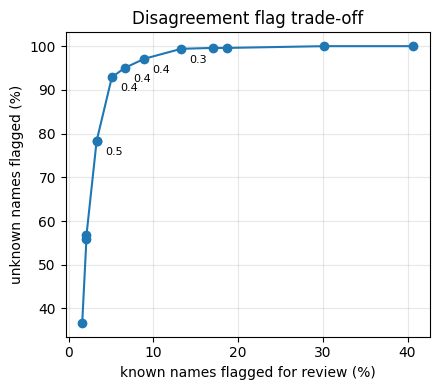

In [ ]:
# Cell 32
import matplotlib.pyplot as plt
assert all(k in globals() for k in ("held", "known", "raw_h", "pick_h", "HOLDOUT")), \
    "re-run the held-out cells (Cell 1-3 of the open-set experiment) first"

# --- baseline on the same held-out and known-name images ---
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
zs_held = zero_shot(reader, held["path"].tolist())
zs_known = zero_shot(reader, known["path"].tolist())
del reader; gc.collect(); torch.cuda.empty_cache()

op = [
    row("Unseen names: pretrained zero-shot", zs_held, held["words"].tolist()),
    row("Unseen names: fine-tuned, never saw them", held["raw"].tolist(), held["words"].tolist()),
    row("Known names: pretrained zero-shot", zs_known, known["words"].tolist()),
    row("Known names: fine-tuned (holdout model)", known["raw"].tolist(), known["words"].tolist()),
]
openset = pd.DataFrame(op)
print("held-out names:", HOLDOUT)
print(openset.to_string(index=False))
openset.to_csv(WORK / "results_open_set.csv", index=False)

# --- flag trade-off: raw-vs-vocabulary disagreement ---
def dis(raw, pick):
    return np.array([edit_distance(r, p) / max(len(p), 1) for r, p in zip(raw, pick)])
dh = dis(raw_h, pick_h)
dk = dis(known["raw"], known["pick"])
pk, tk = np.array(known["pick"]), known["words"].values

sweep = []
for th in np.round(np.arange(0.1, 0.71, 0.05), 2):
    keep = dk <= th
    sweep.append({"threshold": th,
                  "unknown flagged %": 100 * np.mean(dh > th),
                  "unknown accepted wrongly %": 100 * np.mean(dh <= th),
                  "known flagged %": 100 * np.mean(dk > th),
                  "accuracy on accepted known %": 100 * np.mean(pk[keep] == tk[keep]) if keep.any() else np.nan})
sweep = pd.DataFrame(sweep)
other = [c for c in sweep.columns if c != "threshold"]
sweep[other] = sweep[other].round(1)
print(sweep.to_string(index=False))
sweep.to_csv(RESULTS / "results_flag_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(sweep["known flagged %"], sweep["unknown flagged %"], "o-")
for _, r in sweep.iterrows():
    if any(np.isclose(r["threshold"], t) for t in (0.3, 0.4, 0.5)):
        ax.annotate(f'{r["threshold"]:.2f}', (r["known flagged %"], r["unknown flagged %"]),
                    textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("known names flagged for review (%)")
ax.set_ylabel("unknown names flagged (%)")
ax.set_title("Disagreement flag trade-off")
ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(RESULTS / "flag_tradeoff.png", dpi=300)
plt.show()

In [ ]:
# Cell 33
HOLDOUT = ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
hold = set(HOLDOUT)

parts = []
for split in ["medical_train", "medical_val", "medical_test"]:
    d = pd.read_csv(base / split / "labels.csv")
    d = d[d["words"].isin(hold)].copy()
    d["path"] = [str(base / split / f) for f in d["filename"]]
    parts.append(d)
held = pd.concat(parts, ignore_index=True)           # images of the 8 never-trained names
known = test[~test["words"].isin(hold)].copy()       # test images of the 70 trained names
vocab78 = sorted(train_names)
print(len(held), "held-out images |", len(known), "known images |", len(vocab78), "names")

480 held-out images | 700 known images | 78 names


Scaling Test


columns in file: ['name', 'type']
585 distractor names after cleaning | sample: [np.str_('Clomid'), np.str_('Aceclofenac'), np.str_('Isotretinoin'), np.str_('Lamisil'), np.str_('Prazosin'), np.str_('Mebeverine'), np.str_('Amiodarone'), np.str_('Flucloxacillin'), np.str_('Seroquel'), np.str_('Fosamax'), np.str_('Calbo'), np.str_('Doxycycline')]
No Transformation module specified
  32/830 images, 1s
  192/830 images, 7s
  352/830 images, 14s
  512/830 images, 18s
  672/830 images, 22s
  830/830 images, 26s
             vocab size  held mean  held std  known mean  known std  distractor_wins_known mean  distractor_wins_known std  distractor_wins_held mean  distractor_wins_held std
mode    N                                                                                                                                                                      
hardest 0            78       82.7       NaN        96.9        NaN                         0.0                        NaN                

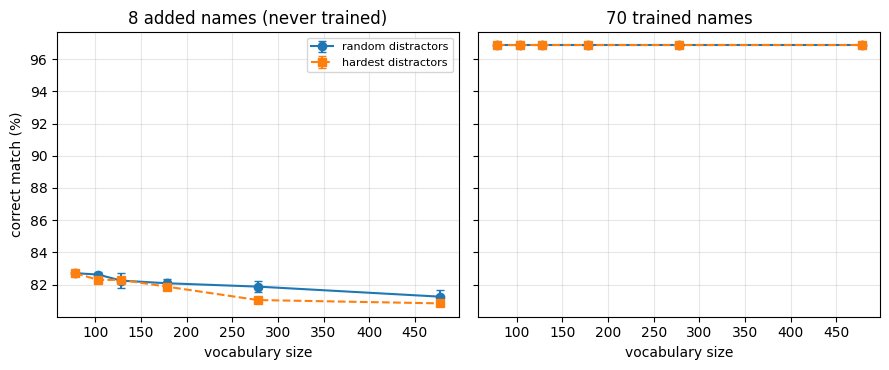

In [ ]:
# Cell 35
import re, time
import matplotlib.pyplot as plt

# ---------------- EDIT THESE ----------------
VOCAB_FILE   = r"D:\Projects\MediLens\medicine_list_generated.csv"   # .csv or .txt, your list of medicine names
NAME_COLUMN  = None      # column with the names; None = first column
POOL_MAX     = 1000      # max distractor names to score
KNOWN_SAMPLE = 350       # known-name test images to use (all 700 = slower)
SIZES        = [0, 25, 50, 100, 200, 400]
DRAWS        = 5         # random distractor draws per size
# --------------------------------------------

# 1) load and clean the distractor pool
vf = Path(VOCAB_FILE)
if vf.suffix.lower() == ".txt":
    raw_names = vf.read_text(encoding="utf-8").splitlines()
else:
    dfv = pd.read_csv(vf, encoding="utf-8-sig")
    print("columns in file:", list(dfv.columns))
    raw_names = dfv[NAME_COLUMN or dfv.columns[0]].astype(str).tolist()

allowed = set(opt.character)
have = {n.lower() for n in vocab78}
seen, pool_names = set(), []
for n in raw_names:
    n = n.strip()
    if (2 <= len(n) <= 20 and re.fullmatch(r"[A-Za-z][A-Za-z\- ]*", n)
            and set(n) <= allowed and n.lower() not in have and n.lower() not in seen):
        seen.add(n.lower()); pool_names.append(n)
rng0 = np.random.default_rng(0)
if len(pool_names) > POOL_MAX:
    pool_names = [pool_names[i] for i in sorted(rng0.choice(len(pool_names), POOL_MAX, replace=False))]
print(f"{len(pool_names)} distractor names after cleaning | sample:", list(rng0.choice(pool_names, 12, replace=False)))
SIZES = [s for s in SIZES if s <= len(pool_names)]

# 2) images: the 8 added names + a sample of the 70 known names
known_s = known.sample(min(KNOWN_SAMPLE, len(known)), random_state=0)
paths  = held["path"].tolist() + known_s["path"].tolist()
truth  = np.array(held["words"].tolist() + known_s["words"].tolist(), dtype=object)
is_held = np.array([True] * len(held) + [False] * len(known_s))
names_all = list(vocab78) + pool_names
names_arr = np.array(names_all, dtype=object)
n78 = len(vocab78)

# 3) score every image against every name once (CTC negative log-likelihood)
@torch.no_grad()
def nll_matrix(model, paths, names, chunk=200):
    chunks = [names[i:i + chunk] for i in range(0, len(names), chunk)]
    enc = [ft_converter.encode(c) for c in chunks]
    M = np.zeros((len(paths), len(names)), dtype=np.float32)
    t0 = time.time()
    for i in range(0, len(paths), 32):
        x = torch.stack([prep(p) for p in paths[i:i + 32]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        for b in range(len(x)):
            col = 0
            for c_names, (v_text, v_len) in zip(chunks, enc):
                Vc = len(c_names)
                lp = logp[b][:, None, :].expand(T, Vc, C).contiguous()
                nll = F.ctc_loss(lp, v_text, torch.full((Vc,), T, dtype=torch.int32), v_len,
                                 blank=0, reduction="none", zero_infinity=True)
                M[i + b, col:col + Vc] = nll.numpy(); col += Vc
        if (i // 32) % 5 == 0:
            print(f"  {i + len(x)}/{len(paths)} images, {time.time() - t0:.0f}s")
    return M

m = load_ft("holdout")
M = nll_matrix(m, paths, names_all)
del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "scaling_nll.npy", M)       # keep it: re-analysing is then instant

# 4) accuracy as the vocabulary grows
def evaluate(cols):
    best = cols[M[:, cols].argmin(1)]
    ok = names_arr[best] == truth
    return {"held": ok[is_held].mean() * 100, "known": ok[~is_held].mean() * 100,
            "distractor_wins_known": (best[~is_held] >= n78).mean() * 100,
            "distractor_wins_held": (best[is_held] >= n78).mean() * 100}

base_idx, pool_idx = np.arange(n78), np.arange(n78, len(names_all))
res = []
for N in SIZES:                                   # random distractors
    for d in range(DRAWS if N else 1):
        cols = base_idx if N == 0 else np.concatenate(
            [base_idx, np.random.default_rng(100 + d).choice(pool_idx, N, replace=False)])
        res.append({"mode": "random", "N": N, "draw": d, **evaluate(cols)})

# worst case: distractors closest in spelling to the 78 real names
close = np.array([min(edit_distance(p.lower(), v.lower()) for v in vocab78) for p in pool_names])
order = pool_idx[np.argsort(close, kind="stable")]
for N in SIZES:
    cols = base_idx if N == 0 else np.concatenate([base_idx, order[:N]])
    res.append({"mode": "hardest", "N": N, "draw": 0, **evaluate(cols)})

R = pd.DataFrame(res)
summary = R.groupby(["mode", "N"]).agg(["mean", "std"]).round(1)
summary.columns = [f"{a} {b}" for a, b in summary.columns]
summary = summary[[c for c in summary.columns if not c.startswith("draw")]]
summary.insert(0, "vocab size", [78 + n for _, n in summary.index])
print(summary.to_string())
summary.to_csv(WORK / "results_scaling.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, key, title in [(axes[0], "held", "8 added names (never trained)"), (axes[1], "known", "70 trained names")]:
    for mode, style in [("random", "o-"), ("hardest", "s--")]:
        s = R[R["mode"] == mode].groupby("N")[key].agg(["mean", "std"]).fillna(0)
        ax.errorbar(78 + s.index, s["mean"], yerr=s["std"], fmt=style, capsize=3, label=f"{mode} distractors")
    ax.set_title(title); ax.set_xlabel("vocabulary size"); ax.grid(alpha=.3)
axes[0].set_ylabel("correct match (%)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(WORK / "scaling.png", dpi=300); plt.show()

# Check if kernel restarted

In [ ]:
# Cell 37
try:
    TRAINER
    print("Variables still in memory: the kernel did NOT restart")
except NameError:
    print("Kernel restarted (or this session never defined TRAINER)")

Variables still in memory: the kernel did NOT restart


In [ ]:
# Cell 38
from pathlib import Path
T = Path(r"D:\Projects\MediLens\EasyOCR\trainer")
for p in [T/"all_data/medical_test/labels.csv",
          T/"config_files/medical_prescription.yaml",
          T/"saved_models/holdout/best_accuracy.pth",
          T/"saved_models/medical_prescription_aug/best_accuracy.pth"]:
    print(p.exists(), p)

True D:\Projects\MediLens\EasyOCR\trainer\all_data\medical_test\labels.csv
True D:\Projects\MediLens\EasyOCR\trainer\config_files\medical_prescription.yaml
True D:\Projects\MediLens\EasyOCR\trainer\saved_models\holdout\best_accuracy.pth
True D:\Projects\MediLens\EasyOCR\trainer\saved_models\medical_prescription_aug\best_accuracy.pth


# NEW dataset

In [ ]:
# Cell 40
import re, hashlib
from pathlib import Path

IMG_DIR = Path(r"D:\Projects\MediLens\Data\kaggle_doctor_hw")           # <- folder holding the images (searched recursively)
CSV     = IMG_DIR / "doctor_handwriting_labels.csv"                # <- edit if the CSV is elsewhere
GEN     = Path(r"D:\Projects\MediLens\medicine_list_generated.csv")

# ---- load, clean labels, drop duplicate photos ----
df = pd.read_csv(CSV, encoding="utf-8-sig")
index = {}
for p in IMG_DIR.rglob("*"):
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        index.setdefault(p.name, p)
df["path"] = df["filename"].map(lambda f: str(index[f]) if f in index else None)
print("rows:", len(df), "| images not found:", df["path"].isna().sum())
df = df.dropna(subset=["path"]).copy()

def norm(s):
    s = s.lower().strip()
    s = re.sub(r"\b(tab|cap|tablet|capsule)\b", " ", s)          # form words are not part of the name
    s = re.sub(r"\d[\d\-\.]*\s*(mg|mcg|ml|g)?\b", " ", s)         # doses
    return re.sub(r"\s+", " ", s).strip()
df["name"] = df["label"].map(norm)
df = df[df["name"] != ""]
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df["path"]]
n0 = len(df); df = df.drop_duplicates("md5")
print(f"dropped {n0 - len(df)} byte-identical duplicates -> {len(df)} images, {df['name'].nunique()} distinct names")

truth, paths = df["name"].tolist(), df["path"].tolist()
title = lambda n: " ".join(w[:1].upper() + w[1:] for w in n.split(" "))   # the model was trained on Title Case
new_names = sorted({title(n) for n in truth})
gen = pd.read_csv(GEN)["name"].tolist()
vocabA = sorted(set(train_names) | set(new_names))     # your 78 + this set's names (name IS in the list)
vocabB = sorted(set(vocabA) | set(gen))                # + 585 distractors

# ---- score ----
def add(rows, label, preds):
    p = [x.lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    L = np.array([len(t) for t in truth])
    rows.append({"system": label, "n": len(p),
                 "exact %": round(100 * np.mean(ed == 0), 1),
                 "within 1 edit %": round(100 * np.mean(ed <= 1), 1),
                 "CER": round(ed.sum() / L.sum(), 3)})

rows = []
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
add(rows, "EasyOCR pretrained, zero-shot (raw)", zero_shot(reader, paths))
del reader; gc.collect(); torch.cuda.empty_cache()

m = load_ft("medical_prescription_aug")
raw, pickA = run(m, ft_converter, paths, vocabA)
_, pickB = run(m, ft_converter, paths, vocabB)
del m; gc.collect(); torch.cuda.empty_cache()
add(rows, "Fine-tuned (augmented), raw", raw)
add(rows, f"Fine-tuned + vocab A ({len(vocabA)} names)", pickA)
add(rows, f"Fine-tuned + vocab B ({len(vocabB)} names)", pickB)
print(pd.DataFrame(rows).to_string(index=False))

out = df[["filename", "label", "name"]].copy()
out["raw"], out["pickA"], out["pickB"] = raw, pickA, pickB
out.to_csv(IMG_DIR.parent / "results_kaggle_doctorhw_per_image.csv", index=False)
out[out["pickA"].str.lower() != out["name"]].head(40)

rows: 89 | images not found: 0
dropped 2 byte-identical duplicates -> 87 images, 41 distinct names
No Transformation module specified
                             system  n  exact %  within 1 edit %   CER
EasyOCR pretrained, zero-shot (raw) 87      1.1              2.3 0.979
        Fine-tuned (augmented), raw 87      5.7             14.9 0.679
   Fine-tuned + vocab A (119 names) 87     43.7             46.0 0.458
   Fine-tuned + vocab B (704 names) 87     39.1             41.4 0.503


,filename,label,name,raw,pickA,pickB
1,IMG_20241006_141949 - Copy.jpg,tab azimax,azimax,ZlAzima,Maxima,Maxima
2,IMG_20241006_142328 - Copy.jpg,tab toniflex,toniflex,l Taittoa,Tridosil,Lipitor
8,IMG_20241006_143544 - Copy.jpg,cap caricef,caricef,lap Cazicrf,Leptic,Leptic
12,IMG_20241006_144252 - Copy.jpg,tab tonoflex p,tonoflex p,Fo Tguar,Fixal,Tramal
14,IMG_20241006_144505 - Copy.jpg,tab dicloran,dicloran,Tas Aicrarl,Bacmax,Vesicare
16,IMG_20241006_144641.jpg,tab provas,provas,Fas Pynas,Maxima,Maxima
17,IMG_20241006_144753.jpg,cap caricef 40mg,caricef,ap as,Vifas,Vifas
18,IMG_20241006_144902.jpg,tab bisleri,bisleri,Ta Bild,Nims,Taxim
20,IMG_20241006_145056.jpg,tab distalgesic,distalgesic,TaiDisfoyooa,Disopan,Taxim
21,IMG_20241006_145141.jpg,tab atcomid,atcomid,FAtcomx,Atcam,Atcam


No Transformation module specified
preprocessing  raw CER  A exact %  A within-1 %  A + tab/cap variants exact %  within-1 %
         gray    0.679       43.7          46.0                          48.3        50.6
        clahe    0.693       44.8          46.0                          49.4        50.6
          ink    0.677       39.1          39.1                          43.7        43.7


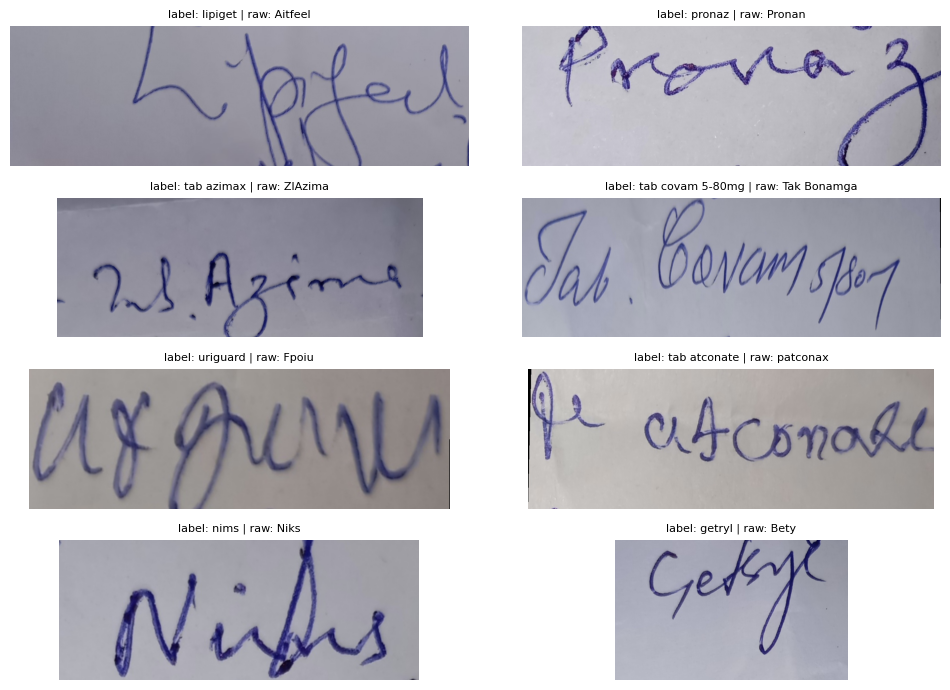

In [ ]:
# Cell 41
import cv2, re

def make_prep(mode):
    def _prep(path, H=64, W=600):
        a = np.asarray(Image.open(path).convert("RGB"))
        if mode == "gray":
            g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
        elif mode == "clahe":
            g = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY))
        elif mode == "ink":            # blue/violet ink has B > R; grey or black print has B ~ R
            d = np.clip(a[..., 2].astype(np.int16) - a[..., 0].astype(np.int16), 0, 255).astype(np.float32)
            d = np.clip(d * 255.0 / max(np.percentile(d, 99.5), 1.0), 0, 255).astype(np.uint8)
            g = 255 - d
        im = Image.fromarray(g)
        w, h = im.size
        nw = min(W, max(1, round(H * w / h)))
        arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
        arr = (arr - 0.5) / 0.5
        out = np.repeat(arr[:, -1:], W, axis=1)
        out[:, :nw] = arr
        return torch.from_numpy(out)[None]
    return _prep

prefixes = ["Tab ", "tab ", "Cap ", "cap "]
vocabC = sorted(set(vocabA) | {p + n for n in new_names for p in prefixes})
strip = lambda s: re.sub(r"^(tab|cap) ", "", s, flags=re.I)
L = np.array([len(t) for t in truth])

def score(preds):
    p = [strip(x).lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    return round(100 * np.mean(ed == 0), 1), round(100 * np.mean(ed <= 1), 1), round(ed.sum() / L.sum(), 3)

prep_orig = prep                       # `run` looks up the global `prep`, so rebinding it switches the mode
m = load_ft("medical_prescription_aug")
res, saved = [], {}
for mode in ["gray", "clahe", "ink"]:
    prep = make_prep(mode)
    raw, pA = run(m, ft_converter, paths, vocabA)
    _, pC = run(m, ft_converter, paths, vocabC)
    saved[mode] = (raw, pA, pC)
    (rE, r1, rC), (aE, a1, _), (cE, c1, _) = score(raw), score(pA), score(pC)
    res.append({"preprocessing": mode, "raw CER": rC,
                "A exact %": aE, "A within-1 %": a1,
                "A + tab/cap variants exact %": cE, "within-1 %": c1})
prep = prep_orig                       # restore for any other cell
del m; gc.collect(); torch.cuda.empty_cache()
print(pd.DataFrame(res).to_string(index=False))

# eyeball: 8 random photos with truth and the raw read (plain grey mode)
import matplotlib.pyplot as plt
raw_g = saved["gray"][0]
pick = np.random.default_rng(0).choice(len(paths), 8, replace=False)
fig, axes = plt.subplots(4, 2, figsize=(10, 7))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(Image.open(paths[i])); ax.axis("off")
    ax.set_title(f'label: {df["label"].iloc[i]} | raw: {raw_g[i]}', fontsize=8)
plt.tight_layout(); plt.show()